# ARTI403 – Image Processing
## Lab 6: Frequency Domain

**Outcome:** Write a program that implements fundamental image processing algorithms.

**Contents**
1. Procedural Task #1 – Laplacian filtering in the frequency domain
2. Assessment Task #1 – Sobel filtering in the frequency domain
3. Verification against spatial-domain convolution

## 0. Imports and setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from skimage import data, io
from skimage.transform import resize
from skimage.util import img_as_ubyte
from scipy.ndimage import convolve

os.makedirs('images', exist_ok=True)

## 1. Procedural Task #1 – Filtering in the Frequency Domain (Laplacian)

The Laplacian in the frequency domain is

**H(u,v) = −4π² (u² + v²)**

so filtering is just **G(u,v) = H(u,v) · F(u,v)**, followed by an inverse FFT.

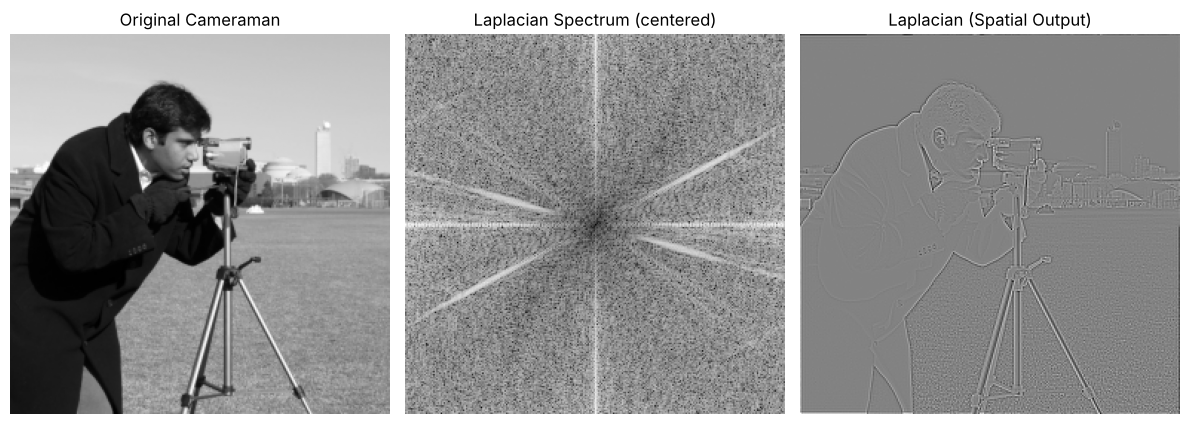

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
# Resize for faster FFT; values now in [0, 1]
image = resize(image, (256, 256))

# Save the image used in this lab
io.imsave('images/cameraman_256.png', img_as_ubyte(image))

# Get image size
M, N = image.shape

# Generate frequency grid (unshifted, matches np.fft.fft2 layout)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Laplacian filter in the frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(fftshift(F_lap))), cmap='gray')
plt.title('Laplacian Spectrum (centered)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.savefig('images/task1_laplacian.png', dpi=120, bbox_inches='tight')
plt.show()

**Observation:** The Laplacian is a high-pass filter (H = 0 at u = v = 0 and grows with frequency), so the
flat regions (sky, coat) go to ~0 and only edges and fine texture remain. In the spectrum, the bright DC
centre of the original is removed and energy is pushed toward the high frequencies.

*(Note: `fftshift` was added only to the spectrum plot so the zero frequency appears in the centre; it does not change the result.)*

## 2. Assessment Task #1 – Sobel Filters in the Frequency Domain

By the **convolution theorem**, convolving the image with a kernel in the spatial domain equals multiplying
their Fourier transforms:

**f ∗ h  ⟺  F(u,v) · H(u,v)**

Steps:
1. Load and resize the image.
2. Zero-pad each 3×3 Sobel kernel to the image size, centre it, then `ifftshift` so the kernel's centre sits at (0,0) – this avoids a spatial shift in the output.
3. Take the FFT of the image and of each padded kernel.
4. Multiply in the frequency domain, inverse FFT, and take the real part.
5. Combine Gx and Gy into the gradient magnitude √(Gx² + Gy²).

In [3]:
# Load and resize image
image = resize(data.camera(), (256, 256))
M, N = image.shape

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=float)

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]], dtype=float)

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    top, left = cy - kh//2, cx - kw//2
    padded[top:top + kh, left:left + kw] = kernel
    # Shift before FFT to place (0,0) at top-left
    return fft2(ifftshift(padded))

# Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters (use the provided function)
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain
G_x_freq = F * H_x
G_y_freq = F * H_y

# Back to the spatial domain
G_x = ifft2(G_x_freq).real
G_y = ifft2(G_y_freq).real
G_mag = np.sqrt(G_x**2 + G_y**2)

print('Image shape        :', image.shape)
print('Gx range           :', G_x.min().round(3), 'to', G_x.max().round(3))
print('Gy range           :', G_y.min().round(3), 'to', G_y.max().round(3))
print('Magnitude max      :', G_mag.max().round(3))

Image shape        : (256, 256)
Gx range           : -3.18 to 3.303
Gy range           : -2.979 to 2.665
Magnitude max      : 3.448


### 2.1 Filter frequency responses |H_x| and |H_y|

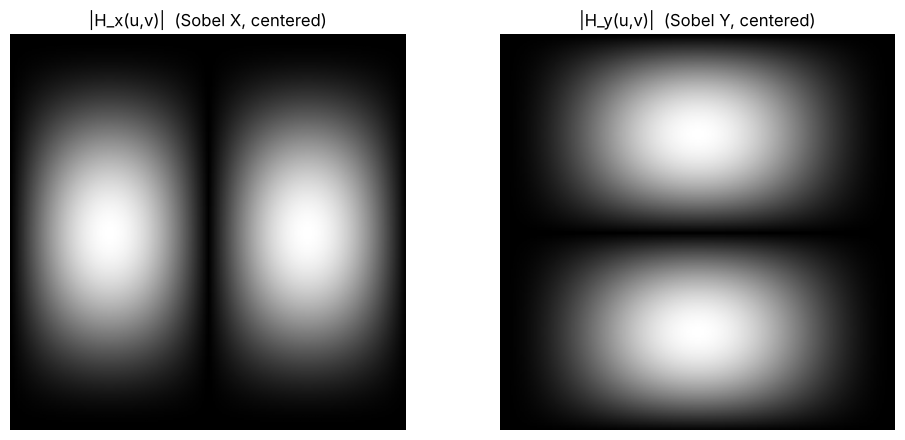

In [4]:
plt.figure(figsize=(10, 4.5))
plt.subplot(1, 2, 1)
plt.imshow(np.abs(fftshift(H_x)), cmap='gray')
plt.title('|H_x(u,v)|  (Sobel X, centered)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(np.abs(fftshift(H_y)), cmap='gray')
plt.title('|H_y(u,v)|  (Sobel Y, centered)')
plt.axis('off')

plt.tight_layout()
plt.savefig('images/task2_sobel_filter_responses.png',
            dpi=120, bbox_inches='tight')
plt.show()

**Observation:** |H_x| is zero along the vertical line v = 0 (no horizontal variation → no response) and
largest at mid-high horizontal frequencies, so Sobel‑X passes **vertical edges**. |H_y| is the same pattern rotated 90°,
so Sobel‑Y passes **horizontal edges**. Both are zero at DC, i.e. they are (band-limited) high-pass / derivative filters.

### 2.2 Spectra and spatial results

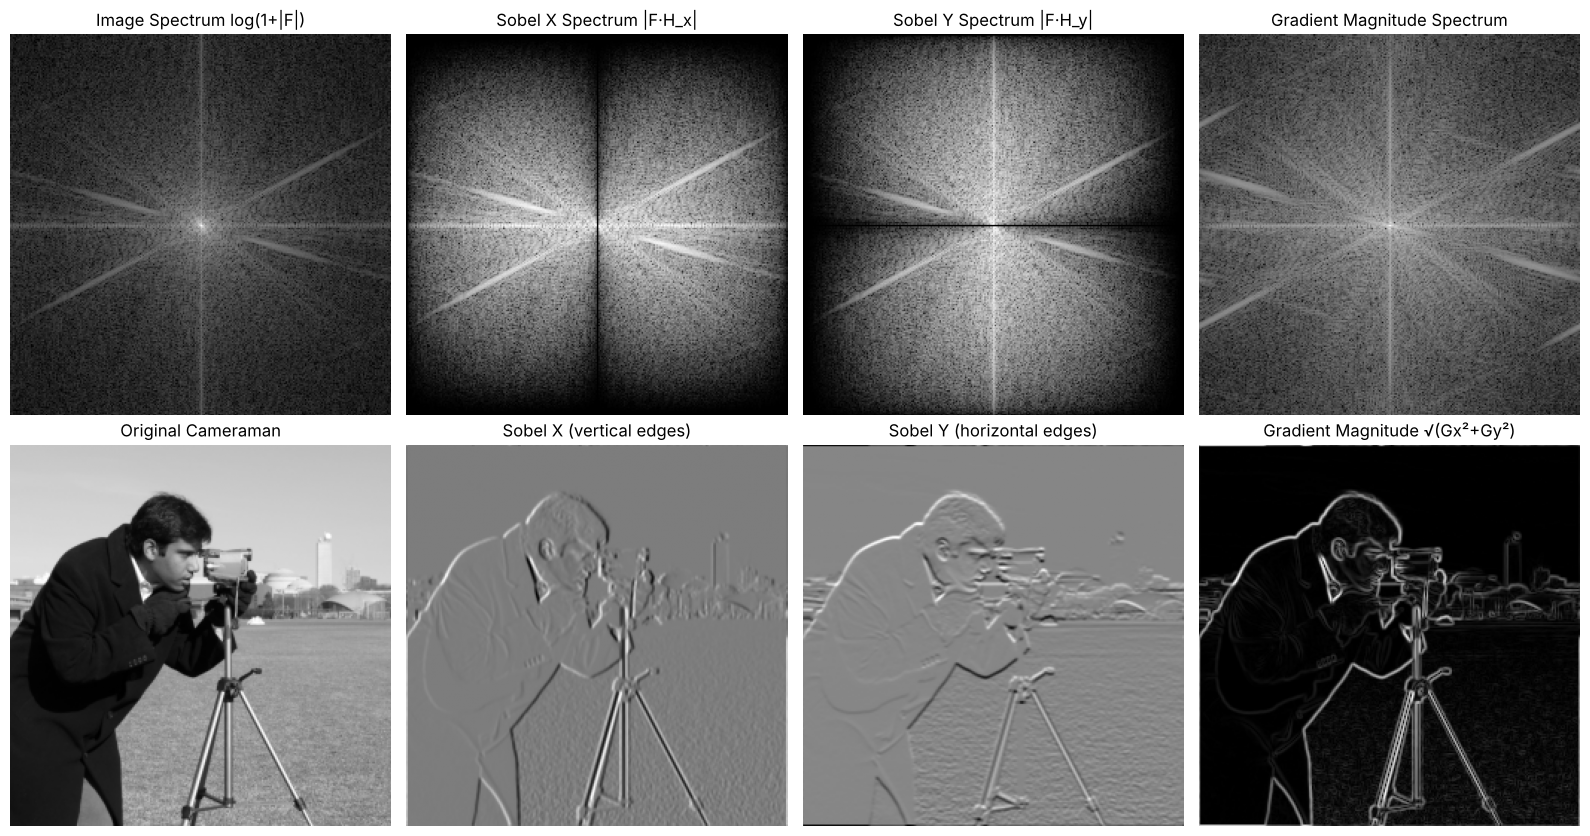

In [5]:
fig, ax = plt.subplots(2, 4, figsize=(16, 8.5))

# Row 1: spectra
ax[0, 0].imshow(np.log(1 + np.abs(fftshift(F))), cmap='gray')
ax[0, 0].set_title('Image Spectrum log(1+|F|)')
ax[0, 1].imshow(np.log(1 + np.abs(fftshift(G_x_freq))), cmap='gray')
ax[0, 1].set_title('Sobel X Spectrum |F·H_x|')
ax[0, 2].imshow(np.log(1 + np.abs(fftshift(G_y_freq))), cmap='gray')
ax[0, 2].set_title('Sobel Y Spectrum |F·H_y|')
G_mag_spec = np.log(1 + np.abs(fftshift(fft2(G_mag))))
ax[0, 3].imshow(G_mag_spec, cmap='gray')
ax[0, 3].set_title('Gradient Magnitude Spectrum')

# Row 2: spatial outputs
ax[1, 0].imshow(image, cmap='gray')
ax[1, 0].set_title('Original Cameraman')
ax[1, 1].imshow(G_x, cmap='gray')
ax[1, 1].set_title('Sobel X (vertical edges)')
ax[1, 2].imshow(G_y, cmap='gray')
ax[1, 2].set_title('Sobel Y (horizontal edges)')
ax[1, 3].imshow(G_mag, cmap='gray')
ax[1, 3].set_title('Gradient Magnitude √(Gx²+Gy²)')

for a in ax.ravel():
    a.axis('off')

plt.tight_layout()
plt.savefig('images/task2_sobel_frequency_domain.png',
            dpi=120, bbox_inches='tight')
plt.show()

**Observation:**
- **Sobel X** responds to intensity changes along the horizontal axis, so it highlights **vertical edges** – the tripod legs, the man's coat outline and the buildings' vertical sides.
- **Sobel Y** responds to changes along the vertical axis, so it highlights **horizontal edges** – the shoulders, camera top and the horizon line.
- The **gradient magnitude** combines both and gives a complete, orientation-independent edge map.
- In the spectra, the low-frequency centre is suppressed and a dark line appears along the axis each filter ignores (v = 0 for X, u = 0 for Y).

## 3. Verification – frequency domain vs. spatial convolution

Multiplying FFTs corresponds to **circular** convolution, so the frequency-domain result should match spatial
convolution with `mode='wrap'` exactly (up to floating-point error). With any other border mode, only the 1‑pixel
border differs.

Max |Gx_freq - Gx_spatial| = 1.4883927423881005e-15
Max |Gy_freq - Gy_spatial| = 2.8380076066980564e-15
Match: True


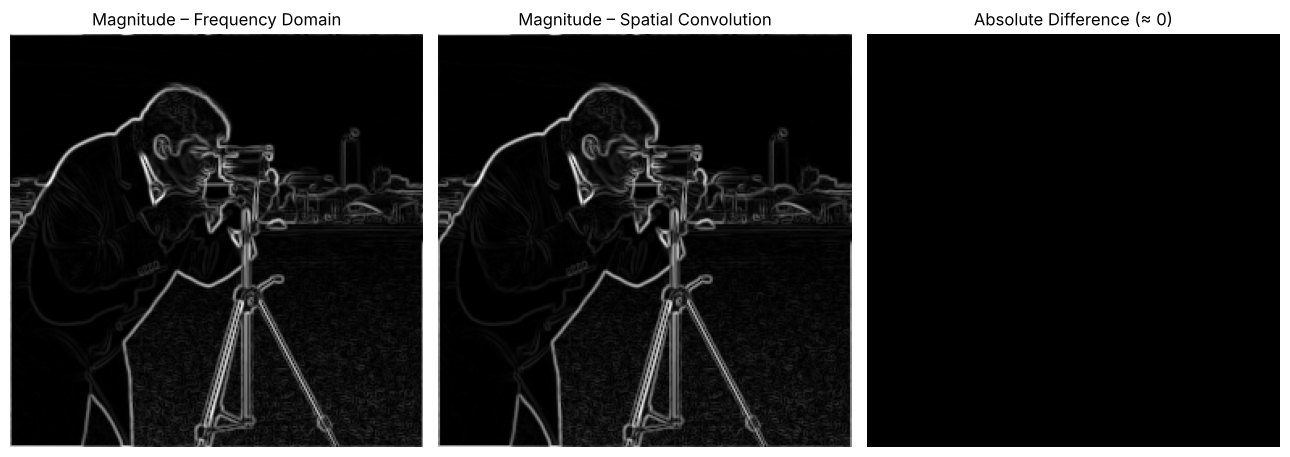

In [6]:
G_x_spatial = convolve(image, sobel_x, mode='wrap')
G_y_spatial = convolve(image, sobel_y, mode='wrap')

print('Max |Gx_freq - Gx_spatial| =', np.abs(G_x - G_x_spatial).max())
print('Max |Gy_freq - Gy_spatial| =', np.abs(G_y - G_y_spatial).max())
print('Match:', np.allclose(G_x, G_x_spatial) and np.allclose(G_y, G_y_spatial))

fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
G_mag_spatial = np.sqrt(G_x_spatial**2 + G_y_spatial**2)
ax[0].imshow(G_mag, cmap='gray')
ax[0].set_title('Magnitude – Frequency Domain')
ax[1].imshow(G_mag_spatial, cmap='gray')
ax[1].set_title('Magnitude – Spatial Convolution')
ax[2].imshow(np.abs(G_mag - G_mag_spatial), cmap='gray',
             vmin=0, vmax=1)
ax[2].set_title('Absolute Difference (≈ 0)')
for a in ax: a.axis('off')
plt.tight_layout()
plt.savefig('images/task2_verification.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Conclusion

- Filtering in the frequency domain is a **point-wise multiplication** G = F · H instead of a sliding-window convolution.
- A small spatial kernel must be **zero-padded to the image size and centred** (`ifftshift`) before its FFT; otherwise the output is shifted.
- The Laplacian and Sobel filters are both **high-pass**: they remove the DC/low-frequency content and keep edges. Sobel is **directional** (X → vertical edges, Y → horizontal edges), while the Laplacian is **isotropic**.
- The frequency-domain Sobel result is identical to spatial circular convolution, confirming the **convolution theorem**.
- Note: `fft2` performs *convolution* (kernel flipped), whereas OpenCV's `filter2D` performs *correlation*; for Sobel this only flips the sign of Gx / Gy, and the magnitude is the same.